In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [5]:
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk #, plot_stitched_height_image_from_vk_2
from scripts_.tilt_correction import baseplane_filter
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.preprocess_vk_data import crop_Vk4File_map
from scripts_.feature_enhancement import feature_enhancement_proceedings#, feature_enhancement_median_clip_high, feature_enhancement_median_clip_high_low, feature_enhancement_2, feature_enhancement_morphological, feature_enhancement_masked

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter

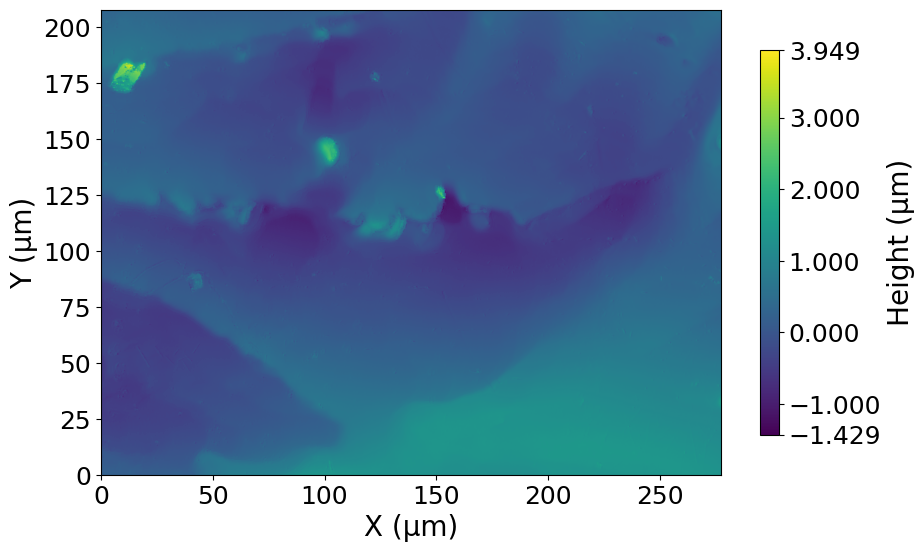

In [216]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 60)

ax = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')

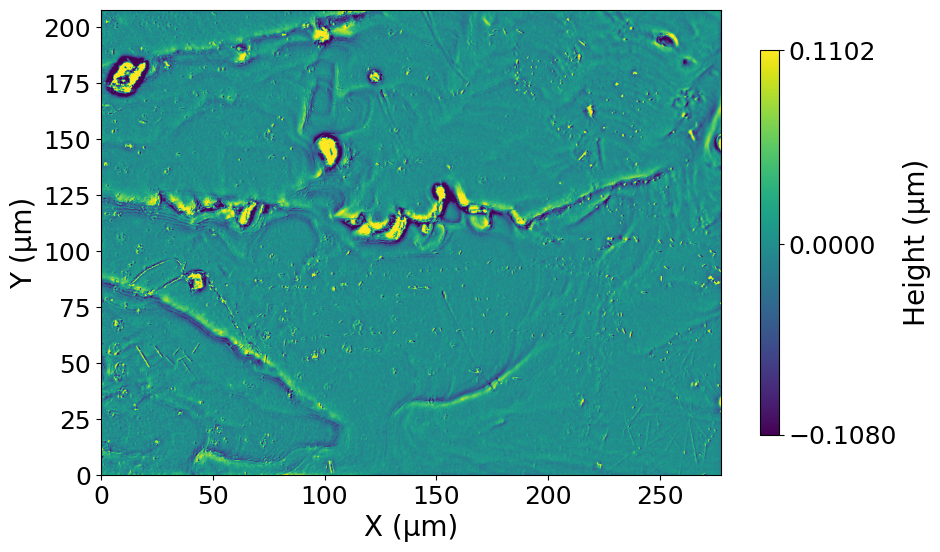

In [ ]:
data_1_vk4_enhanced = feature_enhancement_proceedings(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')
#plt.savefig('plot group meeting height.jpeg')

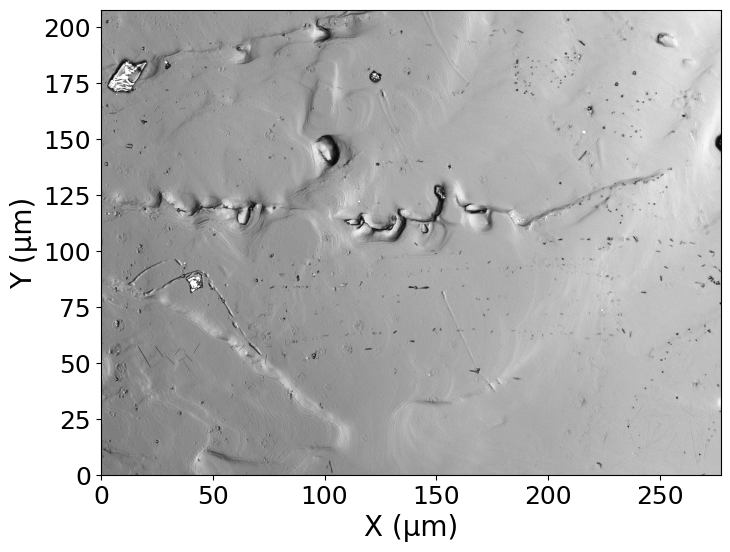

In [6]:
ax = plot_vk4_reflected_light(data_1_vk4)
#plt.savefig('plot group meeting reflected light.jpeg')

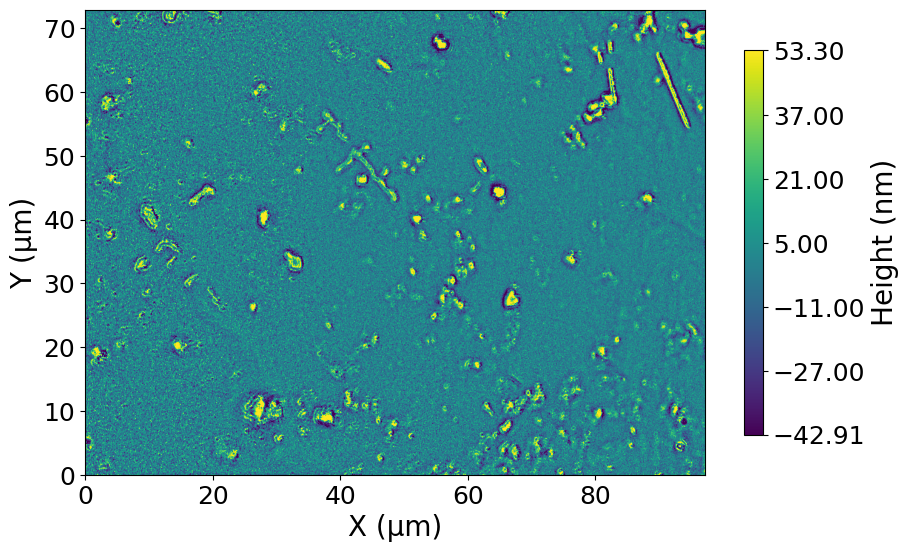

In [259]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

data_4_vk4_tiltcorr = baseplane_filter(data_4_vk4, 80)
data_4_vk4_enhanced = feature_enhancement_proceedings(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced, data_type='feature_enhanced')
#plt.savefig('plot 2 group meeting height.jpeg')
#plt.plot()

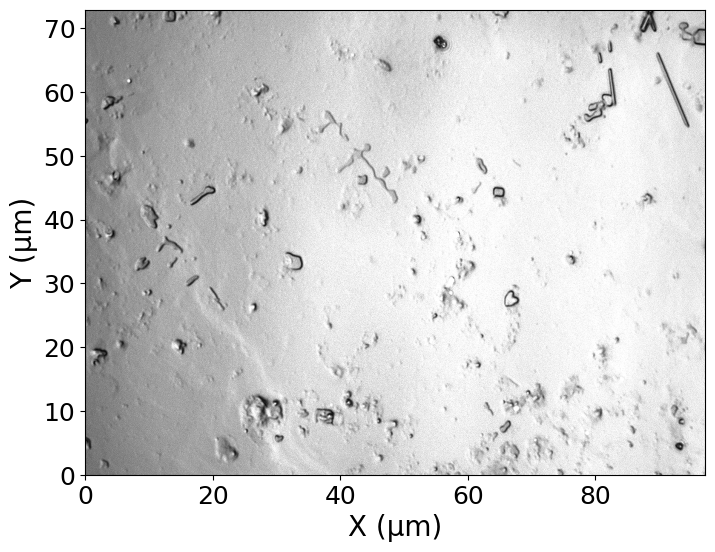

In [145]:
ax = plot_vk4_reflected_light(data_4_vk4)
plt.savefig('plot 2 group meeting reflected light.jpeg')

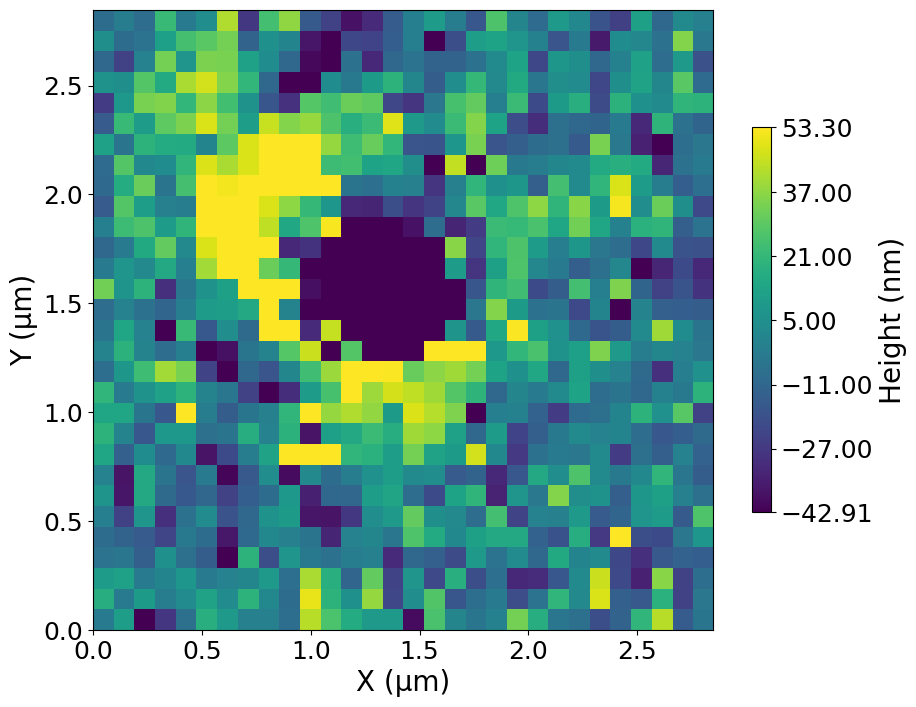

In [260]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')
#plt.savefig('small feature.jpeg')
#plt.plot()

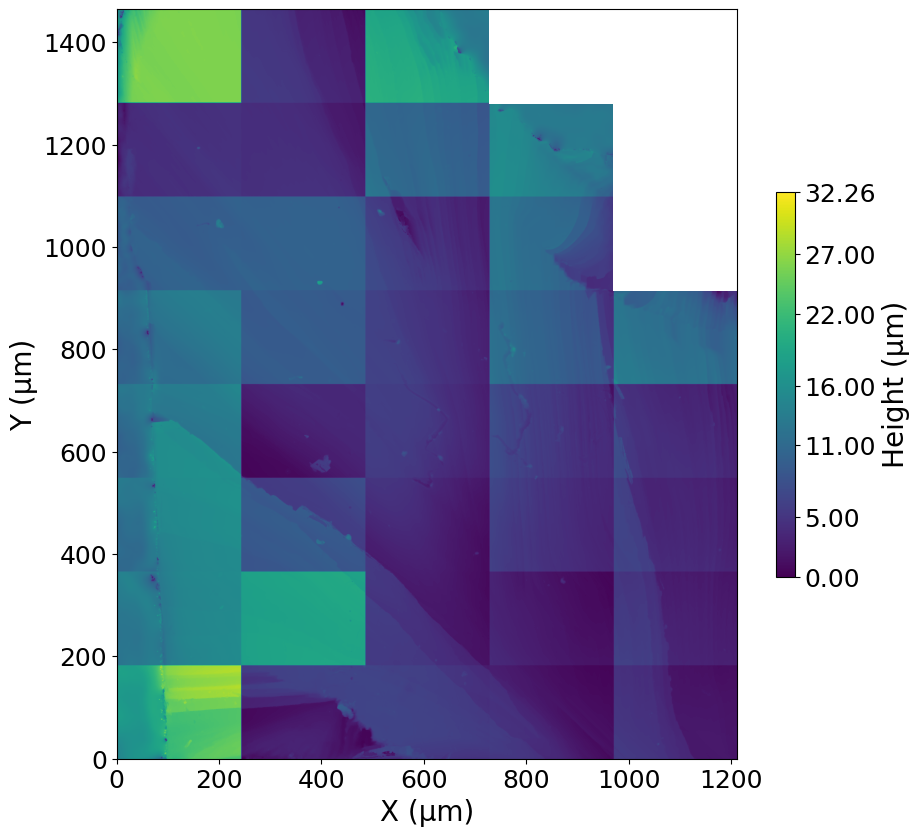

In [147]:
ax = plot_stitched_height_image_from_vk(Path("../raw_data_vk/Sample 4 Milan/Side 2/Stitched 50x left top corner/20260702143459_Y*_X*.vk4"), 'orig', overlap_x_um=35, overlap_y_um=25)
plt.savefig('NaCl sample 4 stitched 50x uncorr.jpeg')

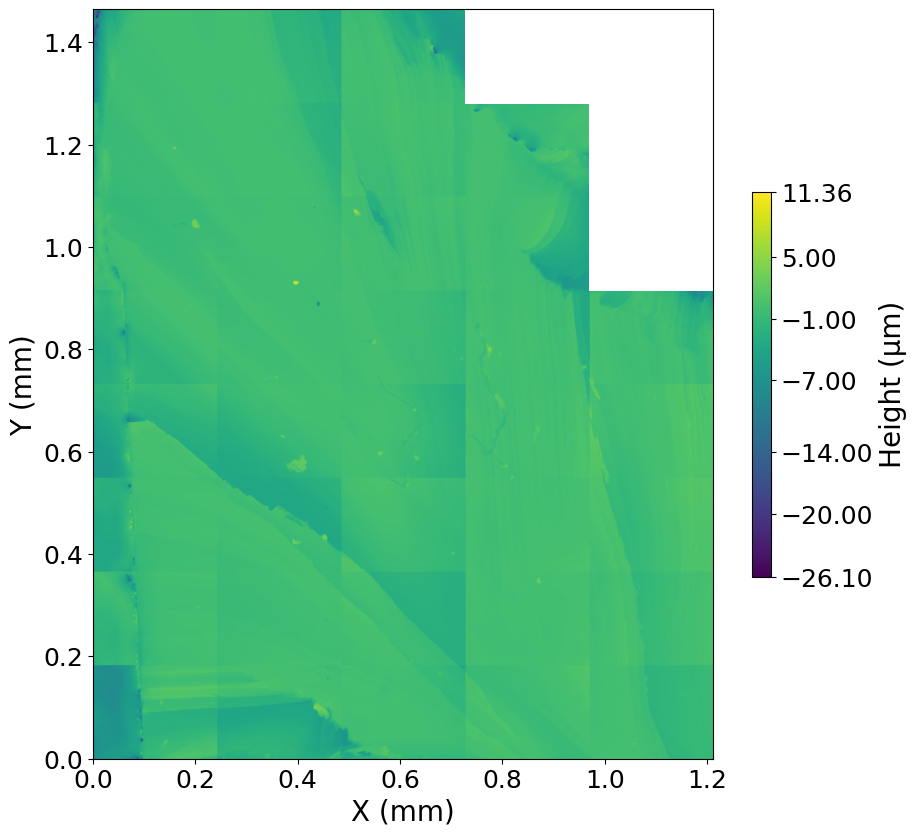

In [6]:
ax = plot_stitched_height_image_from_vk(Path("../raw_data_vk/Sample 4 Milan/Side 2/Stitched 50x left top corner/20260702143459_Y*_X*.vk4"), 'tilt_corr', overlap_x_um=35, overlap_y_um=25)
plt.savefig('NaCl sample 4 stitched 50x processed.jpeg')

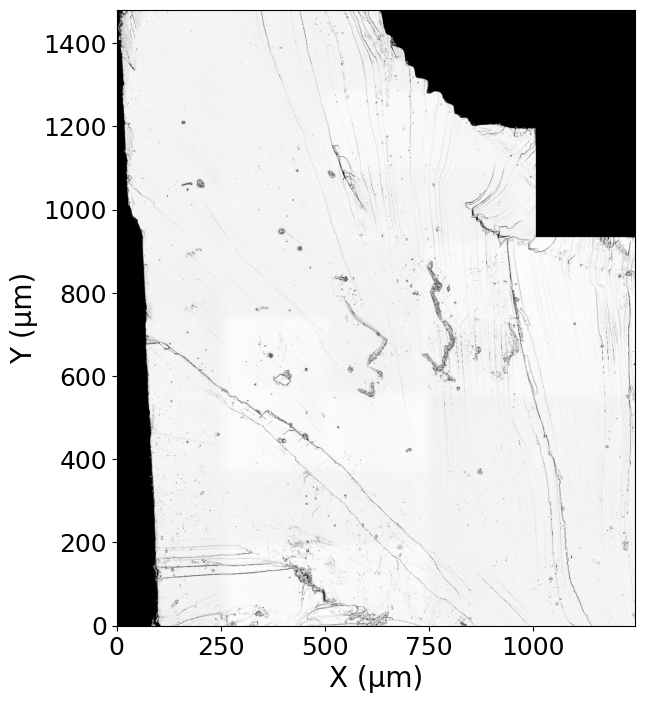

In [149]:
file_name = Path("../raw_data_vk/Sample 4 Milan/Side 2/Stitched 50x left top corner.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


ax = plot_vk4_reflected_light(data_1_vk4)
plt.savefig('NaCl sample 4 auto stitched 50x optical.jpeg')
#plt.plot()